# Fundus_CIMT_2903 — all 5806 images → A/V masks (OCULARNet) — Kaggle FINAL
`data_info.csv` (5806 row) ke master list dhore sob image convert kore, validate kore, ekta **zip** e `/kaggle/working` e save kore.

**Kivabe chalabe**
1. Accelerator **GPU T4**, Internet **ON**.
2. Input e dao: fundus dataset + `data_info.csv` (dataset-er bhetore thakle alada kichu lagbe na).
3. **Save Version → Save & Run All (Commit)** — tahole output (`av_masks.zip`) Kaggle **Output** tab e permanent save hoy.
   (Shudhu "Run All" korle session shesh hole output harabe.)

In [1]:
# ===== CELL 1: CONFIG =====
CFG = dict(
    CSV_PATH  = None,         # None = /kaggle/input e data_info.csv auto-khuje; othoba full path
    IMG_DIR   = None,         # None = /kaggle/input theke auto (csv-r image_name diye match hobe)
    OUT_DIR   = "/kaggle/working/av_masks",
    ZIP_PATH  = "/kaggle/working/av_masks.zip",
    FRESH_START = False,      # True = agey kora output muche notun kore sob 5806 abar korbe
    IM_SIZE   = 1024,
    CROP_FOV  = True,
    BATCH     = 2,
    TTA       = 2,            # 4 = best/slow | 2 = balanced | 1 = fastest
    FP16      = True,
    NUM_WORKERS = 2,
    N_PREVIEW = 12,
    SAVE_GRAY = True,
    CLEAN_AFTER_ZIP = True,   # zip verify hole alada folder muche shudhu zip rakhe (output chhoto + save druto)
)

In [2]:
# ===== CELL 2: SETUP =====
import os, sys, glob, csv, subprocess, urllib.request, shutil, time, zipfile
from pathlib import Path

os.chdir("/kaggle/working")
if not os.path.exists("OCULAR"):
    subprocess.run("git clone -q https://github.com/GonzaloPlaaza/OCULAR.git", shell=True, check=True)
subprocess.run("pip -q install segmentation-models-pytorch timm", shell=True)
sys.path.insert(0, "/kaggle/working/OCULAR")

WPATH = "/kaggle/working/OCULAR/pretrained_weights/OCULARNet/OCULARNet.pth"
os.makedirs(os.path.dirname(WPATH), exist_ok=True)
if not os.path.exists(WPATH) or os.path.getsize(WPATH) < 1e6:
    urllib.request.urlretrieve("https://huggingface.co/Anon-User-Retina/OCULARNet/resolve/main/OCULARNet.pth", WPATH)
print("weights MB:", round(os.path.getsize(WPATH) / 1e6, 1))

import cv2, torch, numpy as np, pandas as pd, torch.nn.functional as F
from PIL import Image
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader
try:
    from utils.get_model import get_model
except Exception as e:
    print("Import fail ->", e, "\n--- repo requirements.txt ---")
    print(open("/kaggle/working/OCULAR/requirements.txt").read()); raise
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev, torch.cuda.get_device_name(0) if dev == "cuda" else "(GPU OFF!)")

model = get_model("base_unet_repvgg_b3", num_classes=4, in_c=3)
ck = torch.load(WPATH, map_location="cpu", weights_only=False)
sd = ck["model_state_dict"] if isinstance(ck, dict) and "model_state_dict" in ck else ck
print(model.load_state_dict(sd)); model.to(dev).eval()

weights MB: 1260.1
device: cuda Tesla T4


model.safetensors: reconstructing file:   0%|          |  0.00B /  493MB            

model.safetensors: downloading bytes:           |  0.00B            

<All keys matched successfully>


Unet(
  (encoder): TimmUniversalEncoder(
    (model): FeatureListNet(
      (stem): RepVggBlock(
        (conv_kxk): ConvNormAct(
          (conv): Conv2d(3, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
          (bn): BatchNormAct2d(
            64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
            (drop): Identity()
            (act): Identity()
          )
        )
        (conv_1x1): ConvNormAct(
          (conv): Conv2d(3, 64, kernel_size=(1, 1), stride=(2, 2), bias=False)
          (bn): BatchNormAct2d(
            64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
            (drop): Identity()
            (act): Identity()
          )
        )
        (drop_path): Identity()
        (attn): Identity()
        (act): ReLU(inplace=True)
      )
      (stages_0): Sequential(
        (0): RepVggBlock(
          (conv_kxk): ConvNormAct(
            (conv): Conv2d(64, 192, kernel_size=(3, 3), stride=(2, 2), padding=(1, 

In [3]:
# ===== CELL 3: MASTER LIST (data_info.csv) + IMAGE PATH MATCH =====
EXT = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}

# csv khujo
csv_path = CFG["CSV_PATH"]
if csv_path is None:
    hits = glob.glob("/kaggle/input/**/data_info.csv", recursive=True)
    csv_path = hits[0] if hits else None
assert csv_path, "data_info.csv paoa jay nai - Input e add koro ba CFG['CSV_PATH'] dao"
info = pd.read_csv(csv_path)
info["image_name"] = info["image_name"].astype(str).str.strip()
print("CSV:", csv_path, "| rows:", len(info), "| unique:", info.image_name.nunique())

# /kaggle/input er sob image-er index (basename -> path)
root = CFG["IMG_DIR"] or "/kaggle/input"
index = {}
for p in Path(root).rglob("*"):
    if p.suffix.lower() in EXT: index.setdefault(p.name, str(p))
print("Images indexed under", root, ":", len(index))

paths = [index.get(n) for n in info.image_name]
missing = [n for n, p in zip(info.image_name, paths) if p is None]
print("Matched:", len(paths) - len(missing), "| MISSING:", len(missing))
if missing: print("  missing examples:", missing[:10])
assert not missing, "Kichu image dataset e nai - upore list dekho"

stems = [Path(n).stem for n in info.image_name]
assert len(set(stems)) == len(stems), "duplicate image_name"

OUT = CFG["OUT_DIR"]
if CFG["FRESH_START"]: shutil.rmtree(OUT, ignore_errors=True)
for d in ["class_png", "color_png", "gray_png", "preview_overlay", "preview_mask_black"]:
    os.makedirs(f"{OUT}/{d}", exist_ok=True)
done_set = set(os.path.splitext(f)[0] for f in os.listdir(f"{OUT}/class_png"))
todo = [i for i, s in enumerate(stems) if s not in done_set]
print(f"Total: {len(paths)} | Already done: {len(paths)-len(todo)} | Remaining: {len(todo)}")

CSV: /kaggle/input/datasets/rofikbme/fundus-image/data_info.csv | rows: 5806 | unique: 5806
Images indexed under /kaggle/input : 11612
Matched: 5806 | MISSING: 0
Total: 5806 | Already done: 0 | Remaining: 5806


In [4]:
# ===== CELL 4: INFERENCE (sob 5806) =====
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
PAL  = {1: (255, 0, 0), 2: (0, 0, 255), 3: (0, 255, 0)}   # artery=Red, vein=Blue, crossing=Green, bg=BLACK
GRAY = np.array([0, 85, 170, 255], np.uint8)

def colorize(cm):
    o = np.zeros((*cm.shape, 3), np.uint8)
    for k, c in PAL.items(): o[cm == k] = c
    return o

def fov_bbox(im):
    H, W = im.shape[:2]
    g = cv2.GaussianBlur(cv2.cvtColor(im, cv2.COLOR_RGB2GRAY), (5, 5), 0)
    ys, xs = np.where(g > 12)
    if len(xs) == 0: return 0, 0, W, H
    x0, x1, y0, y1 = xs.min(), xs.max() + 1, ys.min(), ys.max() + 1
    if (x1 - x0) * (y1 - y0) > 0.97 * H * W or (x1 - x0) < 0.3 * W or (y1 - y0) < 0.3 * H:
        return 0, 0, W, H
    return int(x0), int(y0), int(x1), int(y1)

class DS(Dataset):
    def __len__(self): return len(todo)
    def __getitem__(self, k):
        i = todo[k]
        im = cv2.imread(paths[i], cv2.IMREAD_COLOR)
        if im is None: return ("ERR", i)
        im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
        H, W = im.shape[:2]
        x0, y0, x1, y1 = fov_bbox(im) if CFG["CROP_FOV"] else (0, 0, W, H)
        crop = im[y0:y1, x0:x1]; h, w = crop.shape[:2]; side = max(h, w)
        py, px = (side - h) // 2, (side - w) // 2
        sq = np.zeros((side, side, 3), np.uint8); sq[py:py + h, px:px + w] = crop
        x = cv2.resize(sq, (CFG["IM_SIZE"],) * 2, interpolation=cv2.INTER_LINEAR).astype(np.float32) / 255.
        x = (torch.from_numpy(x.transpose(2, 0, 1)) - MEAN) / STD
        return x, i, (H, W, x0, y0, h, w, side, py, px)

failed = []
def collate(b):
    # unreadable image skip hoy; Cell 5 validation e "missing mask" hishebe dhora porbe
    return [t for t in b if not isinstance(t[0], str)]

@torch.inference_mode()
def forward_tta(x):
    with torch.autocast("cuda", enabled=CFG["FP16"] and dev == "cuda"):
        lg = model(x).float(); n = 1
        if CFG["TTA"] >= 2: lg += model(x.flip(-1)).float().flip(-1); n += 1
        if CFG["TTA"] >= 4:
            lg += model(x.flip(-2)).float().flip(-2)
            lg += model(x.flip(-1, -2)).float().flip(-1, -2); n += 2
    return lg / n

dl = DataLoader(DS(), batch_size=CFG["BATCH"], num_workers=CFG["NUM_WORKERS"], collate_fn=collate)
n_prev = len(os.listdir(f"{OUT}/preview_overlay")); t0 = time.time()

for batch in tqdm(dl, desc="OCULARNet A/V", total=(len(todo) + CFG["BATCH"] - 1) // CFG["BATCH"]):
    if not batch: continue
    x = torch.stack([b[0] for b in batch]).to(dev)
    try:
        prob = torch.softmax(forward_tta(x), dim=1)
    except torch.cuda.OutOfMemoryError:
        torch.cuda.empty_cache()
        prob = torch.cat([torch.softmax(forward_tta(x[j:j+1]), dim=1) for j in range(len(batch))], 0)
    for j, (_, i, (H, W, x0, y0, h, w, side, py, px)) in enumerate(batch):
        try:
            pj = F.interpolate(prob[j:j+1], size=(side, side), mode="bilinear", align_corners=False)
            cm_c = pj.argmax(1)[0].cpu().numpy().astype(np.uint8)[py:py + h, px:px + w]
            cm = np.zeros((H, W), np.uint8); cm[y0:y0 + h, x0:x0 + w] = cm_c
            s = stems[i]; col_bgr = cv2.cvtColor(colorize(cm), cv2.COLOR_RGB2BGR)
            cv2.imwrite(f"{OUT}/color_png/{s}.png", col_bgr)
            if CFG["SAVE_GRAY"]: cv2.imwrite(f"{OUT}/gray_png/{s}.png", GRAY[np.clip(cm, 0, 3)])
            if n_prev < CFG["N_PREVIEW"]:
                cv2.imwrite(f"{OUT}/preview_overlay/{s}.jpg", cv2.addWeighted(cv2.imread(paths[i]), 0.6, col_bgr, 0.4, 0))
                cv2.imwrite(f"{OUT}/preview_mask_black/{s}.png", col_bgr); n_prev += 1
            cv2.imwrite(f"{OUT}/class_png/{s}.png", cm)      # sobar sheshe = "done"
        except Exception as e:
            failed.append((paths[i], str(e)))

print(f"Inference done in {(time.time()-t0)/60:.1f} min | failed: {len(failed)}")
for f in failed[:10]: print("  FAIL:", f)

OCULARNet A/V:   0%|          | 0/2903 [00:00<?, ?it/s]

Inference done in 25.1 min | failed: 0


In [5]:
# ===== CELL 5: VALIDATE ALL 5806 =====
bad_missing, bad_size, empty = [], [], []
for p, s in tqdm(list(zip(paths, stems)), desc="validate"):
    cp = f"{OUT}/class_png/{s}.png"
    if not os.path.exists(cp): bad_missing.append(s); continue
    if Image.open(cp).size != Image.open(p).size: bad_size.append(s)
print(f"class masks present: {len(stems)-len(bad_missing)} / {len(stems)}")
print("missing masks:", len(bad_missing), bad_missing[:10])
print("size mismatch vs original:", len(bad_size), bad_size[:10])
assert not bad_missing, "Kichu mask nai -> Cell 3 + Cell 4 abar chalao (resume kore baki gulo korbe)"

validate:   0%|          | 0/5806 [00:00<?, ?it/s]

class masks present: 5806 / 5806
missing masks: 0 []
size mismatch vs original: 0 []


In [6]:
# ===== CELL 6: MAPPING CSV (+ data_info metadata) =====
rows = []
for n, p, s in zip(info.image_name, paths, stems):
    cm = cv2.imread(f"{OUT}/class_png/{s}.png", cv2.IMREAD_UNCHANGED)
    pid, _, eye = s.rpartition("_")
    rows.append(dict(image_name=n, patient_id=pid, eye=eye, src_path=p,
                     class_mask=f"class_png/{s}.png", color_mask=f"color_png/{s}.png",
                     H=cm.shape[0], W=cm.shape[1],
                     artery_px=int((cm == 1).sum()), vein_px=int((cm == 2).sum()), cross_px=int((cm == 3).sum())))
mp = pd.DataFrame(rows).merge(info, on="image_name", how="left")     # thickness,label,age,gender,group sob ashbe
mp.to_csv(f"{OUT}/mapping.csv", index=False)
print(mp.shape); print(mp[["artery_px", "vein_px", "cross_px"]].describe().T[["mean", "min", "max"]])
print("Images with NO artery/vein:", int(((mp.artery_px + mp.vein_px) == 0).sum()))

with open(f"{OUT}/README.txt", "w") as f:
    f.write("Pseudo A/V masks for Fundus_CIMT_2903 (5806 images) generated by OCULARNet (base_unet_repvgg_b3, github.com/GonzaloPlaaza/OCULAR).\n"
            "class_png: 0=background, 1=artery, 2=vein, 3=crossing (original size, same filename).\n"
            "color_png: artery=red, vein=blue, crossing=green, background=black.\n"
            "gray_png: bg=0, artery=85, vein=170, crossing=255.\n"
            "mapping.csv: image_name + mask paths + pixel counts + data_info.csv columns.\n")

(5806, 17)
                   mean     min      max
artery_px  10396.299001  1989.0  14899.0
vein_px    13220.910265   764.0  19193.0
cross_px     509.982432    16.0   1145.0
Images with NO artery/vein: 0


In [7]:
# ===== CELL 7: ZIP ALL OUTPUT + VERIFY =====
ZIP = CFG["ZIP_PATH"]
if os.path.exists(ZIP): os.remove(ZIP)
files = [f for f in glob.glob(f"{OUT}/**/*", recursive=True) if os.path.isfile(f)]
with zipfile.ZipFile(ZIP, "w", compression=zipfile.ZIP_STORED, allowZip64=True) as z:     # PNG already compressed
    for f in tqdm(files, desc="zipping"):
        z.write(f, arcname=os.path.join("av_masks", os.path.relpath(f, OUT)))
with zipfile.ZipFile(ZIP) as z:
    names = z.namelist(); corrupt = z.testzip()
cnt = {d: sum(n.startswith(f"av_masks/{d}/") for n in names)
       for d in ["class_png", "color_png", "gray_png", "preview_overlay", "preview_mask_black"]}
print("zip files:", len(names), "| corrupt:", corrupt); print(cnt)
assert corrupt is None and cnt["class_png"] == len(stems) and cnt["color_png"] == len(stems), "zip e sob nai!"
print(f"ZIP OK: {ZIP} | {os.path.getsize(ZIP)/1e9:.2f} GB")

if CFG["CLEAN_AFTER_ZIP"]:
    shutil.rmtree(OUT, ignore_errors=True); shutil.rmtree("/kaggle/working/OCULAR", ignore_errors=True)
    print("Cleaned working folders. Output e shudhu:", ZIP)

zipping:   0%|          | 0/17444 [00:00<?, ?it/s]

zip files: 17444 | corrupt: None
{'class_png': 5806, 'color_png': 5806, 'gray_png': 5806, 'preview_overlay': 12, 'preview_mask_black': 12}
ZIP OK: /kaggle/working/av_masks.zip | 0.28 GB
Cleaned working folders. Output e shudhu: /kaggle/working/av_masks.zip


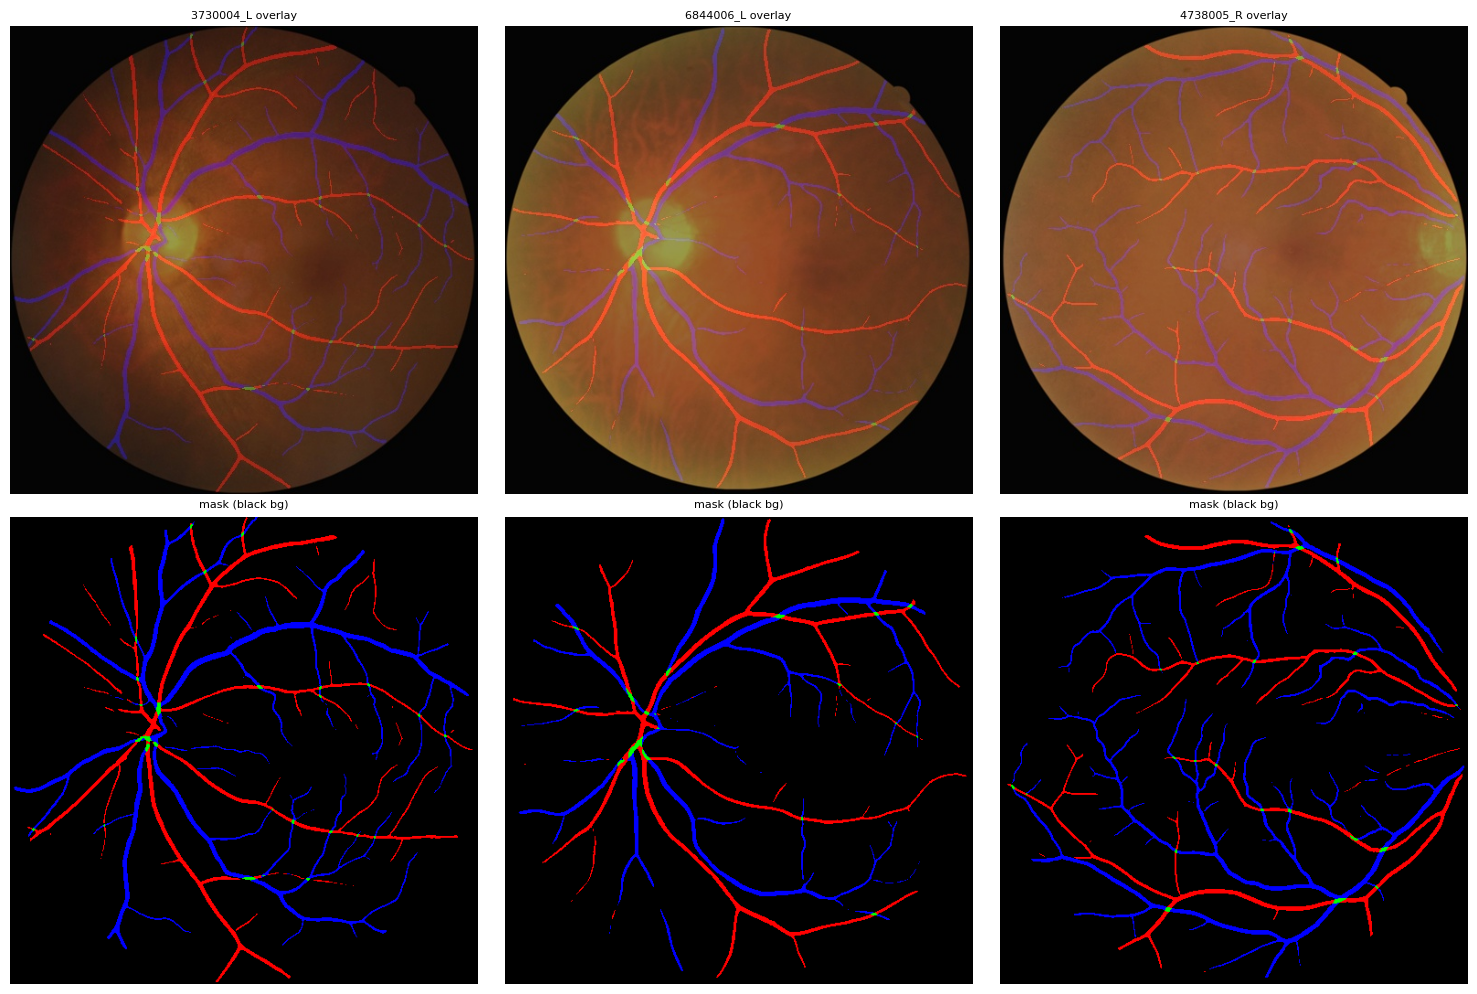

Artery=RED, Vein=BLUE, Crossing=GREEN, BG=BLACK


In [8]:
# ===== CELL 8: (optional) QUICK LOOK =====
# CLEAN_AFTER_ZIP=True hole preview folder muche jay; zip theke dekhte:
import matplotlib.pyplot as plt
with zipfile.ZipFile(CFG["ZIP_PATH"]) as z:
    ov = [n for n in z.namelist() if n.startswith("av_masks/preview_overlay/")][:3]
    mk = [n.replace("preview_overlay", "preview_mask_black").replace(".jpg", ".png") for n in ov]
    fig, ax = plt.subplots(2, len(ov), figsize=(5 * len(ov), 10)); ax = np.atleast_2d(ax).reshape(2, -1)
    for k, (a, b) in enumerate(zip(ov, mk)):
        ax[0, k].imshow(cv2.cvtColor(cv2.imdecode(np.frombuffer(z.read(a), np.uint8), 1), cv2.COLOR_BGR2RGB))
        ax[1, k].imshow(cv2.cvtColor(cv2.imdecode(np.frombuffer(z.read(b), np.uint8), 1), cv2.COLOR_BGR2RGB))
        ax[0, k].set_title(Path(a).stem + " overlay", fontsize=8); ax[1, k].set_title("mask (black bg)", fontsize=8)
    for a in ax.ravel(): a.axis("off")
    plt.tight_layout(); plt.show()
print("Artery=RED, Vein=BLUE, Crossing=GREEN, BG=BLACK")